# Q4 : les périodes où la grille se trompe

> « Sur quelles périodes cette grille tient-elle, et sur lesquelles se trompe-t-elle ? On ne peut pas appliquer un tarif faux en pleine haute saison. »

**Responsable** : Elvis

**Point de départ** : le modèle A retenu en Q3 (régression linéaire sur le logarithme du prix, avec catégorie, ville, mois et week-end), avec les **mêmes plis** de validation croisée.

**Livrable** : la liste des périodes fiables et des périodes à corriger, avec la décision pour chacune (correction automatique du biais ou validation manuelle par le revenue manager).

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/valmont_clean.csv")

# Les 6 réservations aberrantes (séjours de 365 nuits, prix nuls) sont exclues
# des analyses. Seule la question 9 les étudie.
df_modele = df[df["flag_anomalie"] == 0].copy()
print(df.shape, df_modele.shape)  # attendu : (800, 23) (794, 23)

(800, 23) (794, 23)


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ORDRE_CATEGORIES = ["3 étoiles", "4 étoiles", "5 étoiles"]
ORDRE_SAISONS = ["hiver", "printemps", "ete", "automne"]
NOMS_MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin",
             "juil.", "août", "sept.", "oct.", "nov.", "déc."]

## 1. Prédictions hors échantillon, avec les mêmes plis qu'en Q3

`cross_val_predict` découpe les 794 réservations en 5 plis. Chaque réservation est prédite par un modèle entraîné sur les 4 autres plis, donc **un modèle qui ne l'a jamais vue**. Si on mesurait l'erreur sur les données d'entraînement, le modèle aurait déjà « vu la réponse » et l'erreur serait optimiste.

On reprend exactement le modèle et les plis de Q3 (`KFold(n_splits=5, shuffle=True, random_state=42)`), pour que les deux notebooks parlent de la même grille.

In [3]:
VARIABLES = ["categorie", "ville", "mois_sejour", "weekend"]

# Même modèle qu'en Q3 : indicatrices pour les variables catégorielles, weekend tel quel
modele_a = Pipeline([
    ("preparation", ColumnTransformer(
        [("indicatrices", OneHotEncoder(drop="first", handle_unknown="ignore"),
          ["categorie", "ville", "mois_sejour"])],
        remainder="passthrough")),
    ("modele", LinearRegression()),
])

plis = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
log_predit = cross_val_predict(modele_a, df_modele[VARIABLES], np.log(df_modele["prix_nuit_eur"]), cv=plis)

df_modele["prix_predit"] = np.exp(log_predit)
# Trois mesures par réservation :
#  - erreur absolue en euros : de combien la grille se trompe, quel que soit le sens
#  - erreur en % du prix réel : pour comparer un 3 étoiles et un 5 étoiles
#  - biais en % du prix prédit : réel moins prédit, AVEC son signe.
#    Un biais positif veut dire que le client a payé plus que la grille : la grille vend trop bas.
df_modele["erreur_eur"] = (df_modele["prix_nuit_eur"] - df_modele["prix_predit"]).abs()
df_modele["erreur_pct"] = df_modele["erreur_eur"] / df_modele["prix_nuit_eur"] * 100
df_modele["biais_eur"] = df_modele["prix_nuit_eur"] - df_modele["prix_predit"]
df_modele["biais_pct"] = df_modele["biais_eur"] / df_modele["prix_predit"] * 100

ERREUR_GLOBALE = df_modele["erreur_pct"].mean()
print(f"Erreur moyenne globale : {df_modele['erreur_eur'].mean():.2f} € soit {ERREUR_GLOBALE:.2f} %  (identique à Q3)")
print(f"Biais moyen global : {df_modele['biais_eur'].mean():+.2f} € soit {df_modele['biais_pct'].mean():+.2f} %")

Erreur moyenne globale : 19.09 € soit 11.97 %  (identique à Q3)
Biais moyen global : +1.30 € soit +1.06 %


## 2. Erreur et biais par mois et par saison

Pour chaque période : l'effectif (combien de réservations portent le résultat), l'erreur moyenne en euros et en pourcentage, et le biais.

Un biais peut venir du hasard. Pour le savoir, on calcule son intervalle de confiance à 95 % (moyenne ± 1,96 × écart-type / √n). **Si l'intervalle contient 0, le biais n'est pas significatif** : on ne peut pas affirmer que la grille vend trop haut ou trop bas ce mois-là.

In [4]:
def tableau_erreurs(groupes):
    """Effectif, erreur moyenne (€, %), biais moyen (€, %) et intervalle de confiance du biais."""
    t = df_modele.groupby(groupes).agg(
        effectif=("erreur_eur", "size"),
        erreur_eur=("erreur_eur", "mean"),
        erreur_pct=("erreur_pct", "mean"),
        biais_eur=("biais_eur", "mean"),
        biais_pct=("biais_pct", "mean"),
        ecart_type_biais=("biais_pct", "std"),
    )
    demi_ic = 1.96 * t["ecart_type_biais"] / np.sqrt(t["effectif"])
    t["biais_ic_bas_%"] = t["biais_pct"] - demi_ic
    t["biais_ic_haut_%"] = t["biais_pct"] + demi_ic
    t["biais_significatif"] = (t["biais_ic_bas_%"] > 0) | (t["biais_ic_haut_%"] < 0)
    return t.drop(columns="ecart_type_biais")


par_mois = tableau_erreurs("mois_sejour")
par_mois.round(2)

,effectif,erreur_eur,erreur_pct,biais_eur,biais_pct,biais_ic_bas_%,biais_ic_haut_%,biais_significatif
mois_sejour,,,,,,,,
1,74,19.11,12.08,1.39,1.20,-2.58,4.99,False
2,59,20.46,13.31,0.43,1.21,-3.04,5.46,False
3,72,17.45,11.84,2.66,1.26,-2.14,4.67,False
4,64,20.66,14.14,2.37,1.63,-2.83,6.09,False
5,81,21.49,13.76,2.85,1.24,-2.43,4.92,False
6,55,19.73,12.70,3.32,1.44,-2.55,5.44,False
7,54,17.28,9.64,-2.32,0.78,-2.64,4.21,False
8,87,19.70,10.33,0.18,0.76,-2.09,3.61,False
9,57,19.73,12.76,0.32,1.13,-3.11,5.36,False


In [5]:
par_saison = tableau_erreurs("saison").loc[ORDRE_SAISONS]
par_saison.round(2)

,effectif,erreur_eur,erreur_pct,biais_eur,biais_pct,biais_ic_bas_%,biais_ic_haut_%,biais_significatif
saison,,,,,,,,
hiver,203,19.50,11.84,1.18,0.89,-1.21,2.99,False
printemps,217,19.90,13.23,2.65,1.36,-0.84,3.56,False
ete,196,19.04,10.81,0.37,0.96,-0.97,2.88,False
automne,178,17.66,11.87,0.82,1.00,-1.19,3.18,False


**Interprétation**

- **Aucun mois et aucune saison n'a de biais significatif** : les 12 intervalles de confiance contiennent 0. Les biais moyens vont de −2 € (juillet) à +3 € (juin). La grille ne vend donc ni systématiquement trop haut ni systématiquement trop bas sur une période, haute saison comprise.
- Le biais global, légèrement positif (environ +1 %), vient du retour par l'exponentielle : `exp(moyenne des log)` donne le prix *médian* d'un profil, un peu sous le prix moyen. Il est trop faible pour changer une décision. C'est la limite déjà notée en Q3.
- **Ce qui varie selon les mois, c'est la précision, pas le sens de l'erreur** : de 9,6 % en juillet à 14,1 % en avril. Le printemps est la saison la moins précise (13,2 %), l'été la plus précise (10,8 %).

## 3. Découpage par catégorie : la grille se trompe-t-elle davantage en 5 étoiles ?

In [6]:
par_categorie = tableau_erreurs("categorie").loc[ORDRE_CATEGORIES]
par_categorie.round(2)

,effectif,erreur_eur,erreur_pct,biais_eur,biais_pct,biais_ic_bas_%,biais_ic_haut_%,biais_significatif
categorie,,,,,,,,
3 étoiles,306,16.83,16.45,1.79,1.82,-0.37,4.01,False
4 étoiles,265,17.05,10.63,1.10,0.84,-0.76,2.45,False
5 étoiles,223,24.60,7.43,0.86,0.28,-0.91,1.47,False


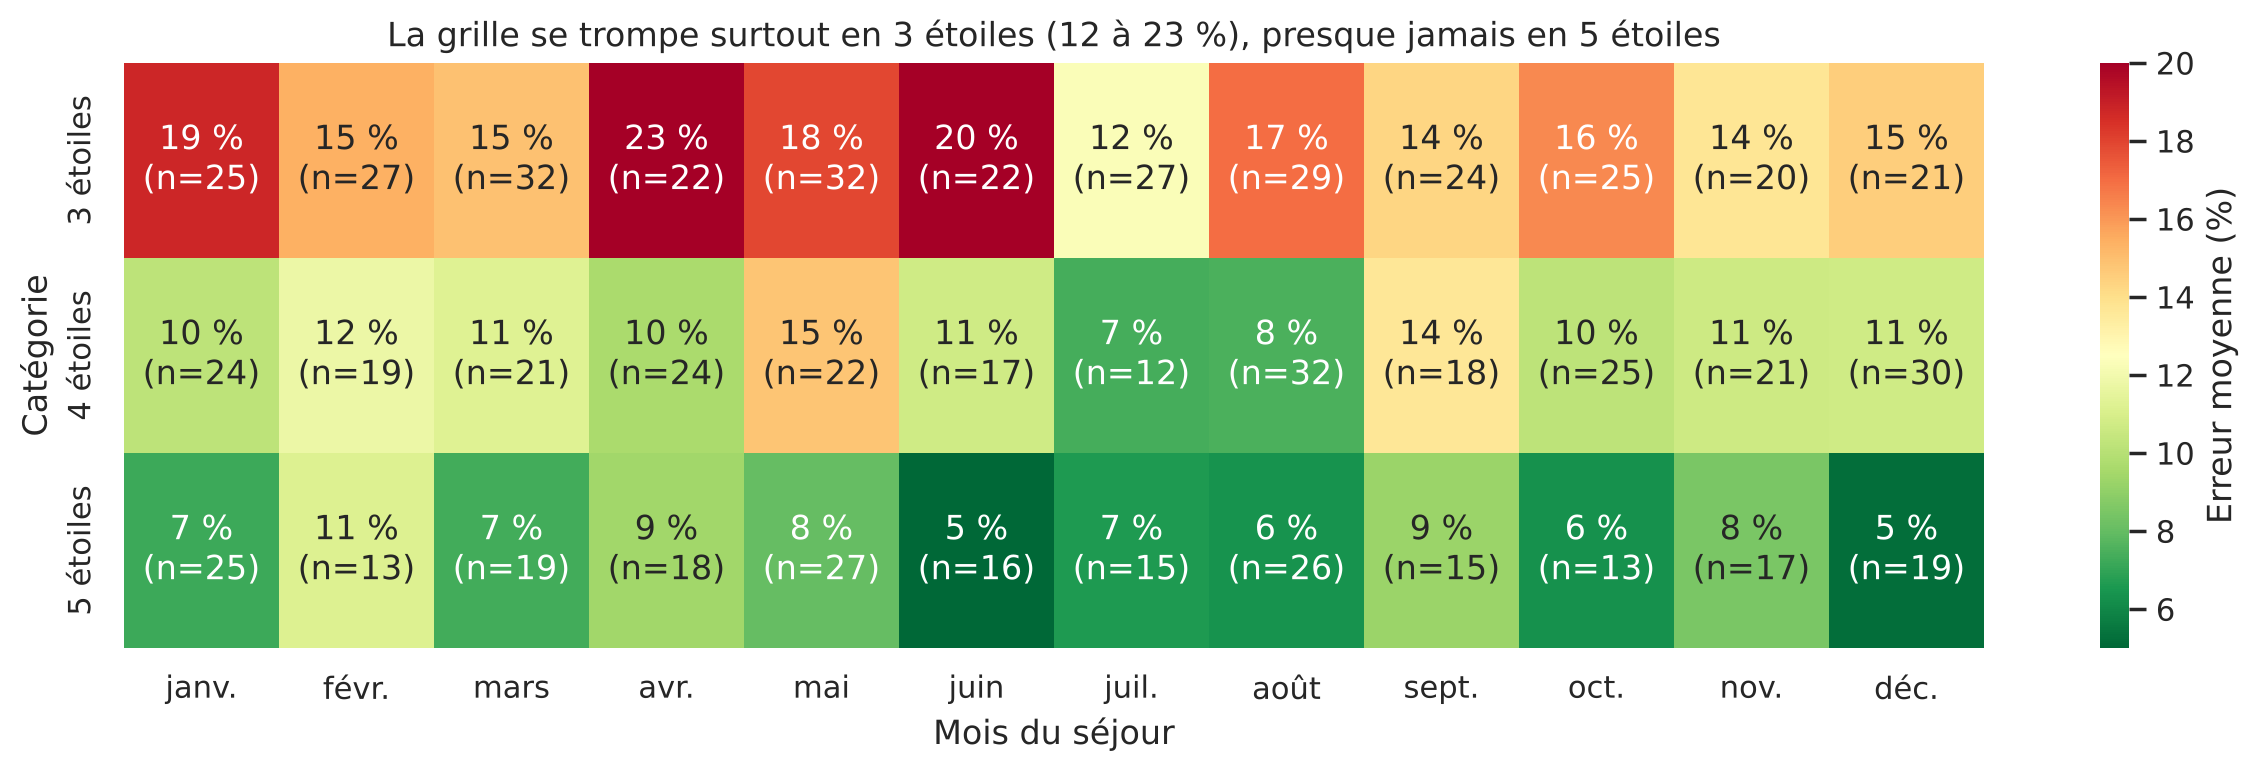

In [7]:
# Croisement mois x catégorie : erreur en %, avec l'effectif de chaque case.
# Les cases sont petites (13 à 39 réservations) : on affiche l'effectif à côté de l'erreur.
erreur_mc = df_modele.pivot_table(index="categorie", columns="mois_sejour", values="erreur_pct", aggfunc="mean").loc[ORDRE_CATEGORIES]
effectif_mc = df_modele.pivot_table(index="categorie", columns="mois_sejour", values="erreur_pct", aggfunc="size").loc[ORDRE_CATEGORIES]
etiquettes = erreur_mc.round(0).astype(int).astype(str) + " %\n(n=" + effectif_mc.astype(str) + ")"

fig, ax = plt.subplots(figsize=(15, 3.8))
sns.heatmap(erreur_mc, annot=etiquettes, fmt="", cmap="RdYlGn_r", vmin=5, vmax=20,
            cbar_kws={"label": "Erreur moyenne (%)"}, ax=ax)
ax.set_xticklabels(NOMS_MOIS)
ax.set_xlabel("Mois du séjour")
ax.set_ylabel("Catégorie")
ax.set_title("La grille se trompe surtout en 3 étoiles (12 à 23 %), presque jamais en 5 étoiles")
plt.show()

**Interprétation**

**Non, la grille ne se trompe pas davantage en 5 étoiles, c'est l'inverse.** Tout dépend de l'unité :

| Catégorie | Erreur en € | Erreur en % | Lecture |
| --- | --- | --- | --- |
| 3 étoiles | 16,83 € | **16,5 %** | la moins fiable : prix très dispersés autour de la grille |
| 4 étoiles | 17,05 € | 10,6 % | correcte |
| 5 étoiles | 24,60 € | **7,4 %** | la plus fiable en proportion |

En 5 étoiles, l'erreur paraît plus forte en euros (24,60 €) seulement parce que les prix y sont trois fois plus élevés. Rapportée au prix, c'est la catégorie la mieux tarifée. Le croisement montre que les erreurs fortes sont toutes en **3 étoiles** : avril (23 %), juin (20 %), janvier (19 %), mai (18 %) et août (17 %).

## 4. Graphique : erreur et biais par mois

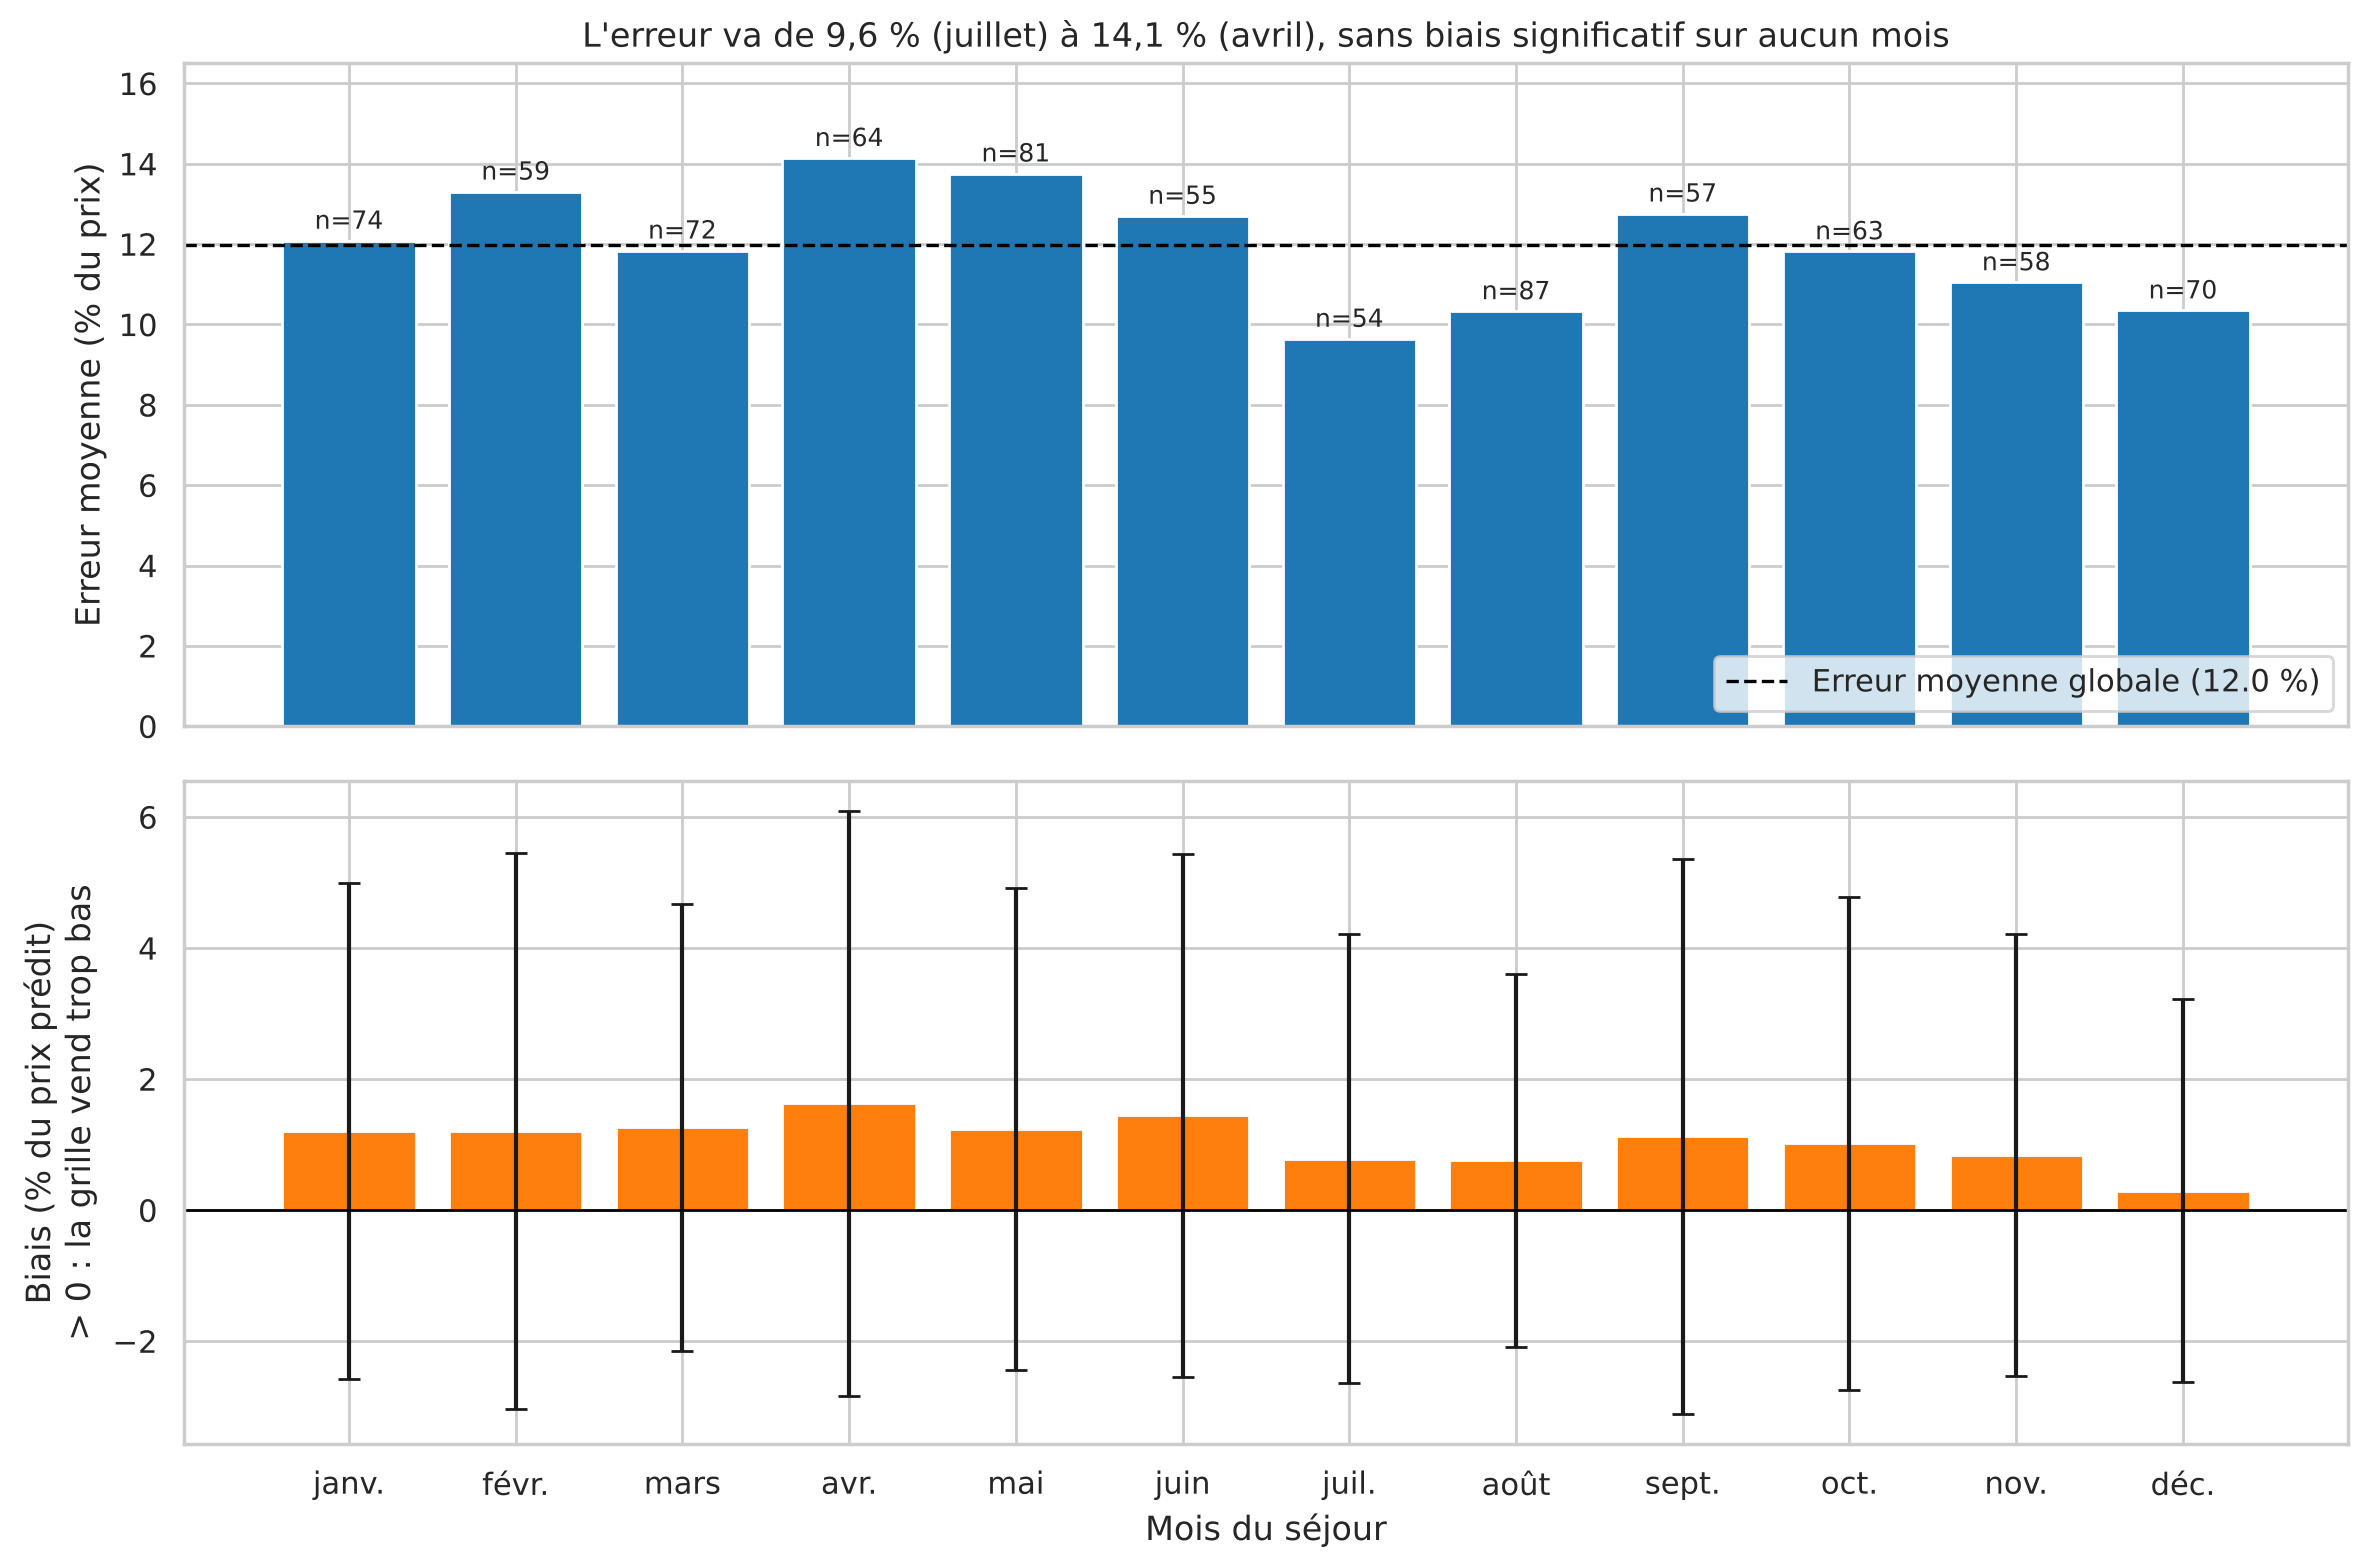

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
mois = par_mois.index

# Erreur en % par mois, avec la ligne de l'erreur moyenne globale et le seuil retenu (section 5)
ax1.bar(mois, par_mois["erreur_pct"], color="tab:blue")
ax1.axhline(ERREUR_GLOBALE, color="black", ls="--", lw=1.2, label=f"Erreur moyenne globale ({ERREUR_GLOBALE:.1f} %)")
for m, e, n in zip(mois, par_mois["erreur_pct"], par_mois["effectif"]):
    ax1.text(m, e + 0.3, f"n={n}", ha="center", fontsize=9)
ax1.set_ylabel("Erreur moyenne (% du prix)")
ax1.set_ylim(0, 16.5)
ax1.legend(loc="lower right")
ax1.set_title("L'erreur va de 9,6 % (juillet) à 14,1 % (avril), sans biais significatif sur aucun mois")

# Biais en % par mois avec son intervalle de confiance à 95 %
erreurs_ic = [par_mois["biais_pct"] - par_mois["biais_ic_bas_%"], par_mois["biais_ic_haut_%"] - par_mois["biais_pct"]]
ax2.bar(mois, par_mois["biais_pct"], yerr=erreurs_ic, capsize=4, color="tab:orange")
ax2.axhline(0, color="black", lw=1)
ax2.set_ylabel("Biais (% du prix prédit)\n> 0 : la grille vend trop bas")
ax2.set_xlabel("Mois du séjour")
ax2.set_xticks(list(mois), NOMS_MOIS)

plt.tight_layout()
plt.show()

## 5. Le seuil : quand une période est-elle fiable ?

**Règle retenue, écrite avant de classer les mois** :

1. **Biais** : si le biais d'un mois est significatif (intervalle à 95 % qui exclut 0), la grille se trompe dans un sens connu. On peut alors la **corriger automatiquement** en appliquant ce biais au prix du mois.
2. **Précision** : un mois est **fiable** si son erreur moyenne ne dépasse pas **12 %**. C'est l'erreur annoncée de la grille en Q3, donc la tolérance de ±12 % donnée au revenue manager. Au-delà, la tolérance annoncée ne tient pas : les prix du mois passent en **validation manuelle**.

**Pourquoi 12 % et pas 10 %** : un seuil de 10 % classerait 11 mois sur 12 « à corriger » (seul juillet passe). Cette exigence dépasse la précision du modèle lui-même : elle mettrait toute l'année en validation manuelle et ne permettrait plus de distinguer les mois. Le calcul à 10 % est affiché plus bas comme test de sensibilité.

In [9]:
SEUIL_ERREUR = 12.0  # en %, la tolérance annoncée au revenue manager en Q3

def classer(ligne):
    if ligne["biais_significatif"]:
        return "à corriger : biais (correction automatique)"
    if ligne["erreur_pct"] > SEUIL_ERREUR:
        return "à corriger : imprécis (validation manuelle)"
    return "fiable"

classement = par_mois[["effectif", "erreur_eur", "erreur_pct", "biais_pct", "biais_significatif"]].copy()
classement.insert(0, "mois", NOMS_MOIS)
classement["haute_saison"] = classement.index.isin([6, 7, 8, 12])
classement["statut"] = classement.apply(classer, axis=1)
classement.round(2)

,mois,effectif,erreur_eur,erreur_pct,biais_pct,biais_significatif,haute_saison,statut
mois_sejour,,,,,,,,
1,janv.,74,19.11,12.08,1.20,False,False,à corriger : imprécis (validation manuelle)
2,févr.,59,20.46,13.31,1.21,False,False,à corriger : imprécis (validation manuelle)
3,mars,72,17.45,11.84,1.26,False,False,fiable
4,avr.,64,20.66,14.14,1.63,False,False,à corriger : imprécis (validation manuelle)
5,mai,81,21.49,13.76,1.24,False,False,à corriger : imprécis (validation manuelle)
6,juin,55,19.73,12.70,1.44,False,True,à corriger : imprécis (validation manuelle)
7,juil.,54,17.28,9.64,0.78,False,True,fiable
8,août,87,19.70,10.33,0.76,False,True,fiable
9,sept.,57,19.73,12.76,1.13,False,False,à corriger : imprécis (validation manuelle)


In [10]:
# Test de sensibilité : combien de mois seraient "fiables" selon le seuil choisi ?
for seuil in [10, 12, 13, 15]:
    fiables = (par_mois["erreur_pct"] <= seuil) & ~par_mois["biais_significatif"]
    liste = ", ".join(np.array(NOMS_MOIS)[fiables.values])
    print(f"Seuil {seuil:>2} % : {fiables.sum():>2} mois fiables  ({liste})")

Seuil 10 % :  1 mois fiables  (juil.)
Seuil 12 % :  6 mois fiables  (mars, juil., août, oct., nov., déc.)
Seuil 13 % :  9 mois fiables  (janv., mars, juin, juil., août, sept., oct., nov., déc.)
Seuil 15 % : 12 mois fiables  (janv., févr., mars, avr., mai, juin, juil., août, sept., oct., nov., déc.)


In [11]:
# Où se trouve l'imprécision des mois "à corriger" ? Erreur par catégorie sur ces mois uniquement.
mois_a_corriger = classement.index[classement["statut"] != "fiable"]
detail = (df_modele[df_modele["mois_sejour"].isin(mois_a_corriger)]
          .groupby("categorie")["erreur_pct"].agg(effectif="size", erreur_pct="mean")
          .loc[ORDRE_CATEGORIES].round(2))
print("Mois à corriger :", ", ".join(np.array(NOMS_MOIS)[mois_a_corriger - 1]))
detail

Mois à corriger : janv., févr., avr., mai, juin, sept.


,effectif,erreur_pct
categorie,,
3 étoiles,152,18.06
4 étoiles,124,11.72
5 étoiles,114,8.13


**Interprétation et classement**

| Statut | Mois | Erreur |
| --- | --- | --- |
| **Fiable** | mars, juillet, août, octobre, novembre, décembre | 9,6 à 11,8 % |
| **À corriger : imprécis** | janvier, février, avril, mai, juin, septembre | 12,1 à 14,1 % |
| **À corriger : biais** | aucun | — |

- **Haute saison** : juillet, août et décembre sont **fiables** (9,6 à 10,4 %). **Juin est le seul mois de haute saison à surveiller** (12,7 %).
- **Aucun mois n'a besoin d'une correction automatique** : aucun biais n'est significatif. Décaler les prix d'un mois corrigerait du hasard et dégraderait la grille.
- Sur les six mois imprécis, l'erreur vient surtout des **3 étoiles** (18,1 %, contre 11,7 % en 4 étoiles et 8,1 % en 5 étoiles sur ces mêmes mois).

## Fiche réponse Q4

1. **Compréhension** : la direction veut savoir sur quels mois elle peut appliquer la grille de Q3 sans contrôle, et sur lesquels un tarif faux risque de passer, surtout en haute saison.

2. **Méthode** : prédictions hors échantillon (`cross_val_predict`, mêmes 5 plis qu'en Q3), pour que chaque réservation soit jugée par un modèle qui ne l'a pas vue. Pour chaque mois, saison et catégorie : erreur moyenne en euros et en pourcentage, et biais (réel moins prédit) avec un intervalle de confiance à 95 %. L'intervalle de confiance permet de séparer une vraie dérive d'un écart dû au hasard, ce qu'une moyenne seule ne fait pas avec 54 à 87 réservations par mois.

3. **Vérifications** : erreur globale identique à Q3 (19,09 €, 12,0 %) ; effectifs affichés à côté de chaque erreur ; seuil écrit avant de classer, puis test de sensibilité de 10 % à 15 %.

4. **Résultat** : **6 mois fiables** (mars, juillet, août, octobre, novembre, décembre), **6 mois imprécis** (janvier, février, avril, mai, juin, septembre, de 12,1 à 14,1 %), **0 mois biaisé**. En haute saison, seul juin dépasse la tolérance. L'erreur est de **16,5 % en 3 étoiles** contre **7,4 % en 5 étoiles**.

5. **Décision** :
   - **Pas de correction automatique** : aucun biais n'est significatif. Corriger reviendrait à corriger du bruit.
   - **Validation manuelle** par le revenue manager des prix **3 étoiles** sur les six mois imprécis, et en priorité **juin** (haute saison, 12,7 %). C'est en 3 étoiles que la tolérance de ±12 % ne tient pas.
   - **Application directe** de la grille partout ailleurs, notamment les 4 et 5 étoiles toute l'année et les mois de juillet, août et décembre.

6. **Gain** : le contrôle manuel est concentré là où il sert. Il porte sur environ **19 % des réservations** (les 3 étoiles des six mois imprécis), au lieu de tout vérifier. Les 81 % restants, dont toute la haute saison 4 et 5 étoiles, sont tarifés automatiquement avec une erreur connue.

7. **Limites et axes d'amélioration** :
   - Les cases mois × catégorie sont petites (13 à 39 réservations) : le classement de chaque case reste fragile. Il faudra le refaire avec une année de données en plus.
   - L'imprécision des 3 étoiles n'est pas expliquée par les variables actuelles : un effet propre à chaque hôtel, la taille ou la distance à la gare sont à tester.
   - Le seuil de 12 % est un choix métier : à valider avec le revenue manager.